# Previsão da tendência do Ibovespa

Tech Challenge 2 · Pós-graduação em Data Analytics · FIAP

O código conserva os modelos e as escolhas da entrega acadêmica. As seções 4, 6 e 7 explicam quais resultados podem ser interpretados como teste temporal e quais são ilustrativos.

In [1]:
# Importando bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import xgboost as xgb

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf as _plot_acf
from statsmodels.graphics.tsaplots import plot_pacf as _plot_pacf

from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

import warnings
from pandas.errors import SettingWithCopyWarning
warnings.simplefilter(action="ignore", category=SettingWithCopyWarning)
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore")
sns.set_style("darkgrid")

In [2]:
# Funcoes
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return mae, mse, mape

def metrics_to_df(metrics, model_name):
    mae, mse, mape = metrics

    return pd.DataFrame(
        {
            "MAE": [mae],
            "MSE": [mse],
            "MAPE (%)": [mape],
        },
        index=[model_name]
    )

def plot_acf(data, lags=365, title="Autocorrelação da Série Temporal"):
    fig, ax = plt.subplots(figsize=(15, 5))
    # Get the ACF values and confidence intervals
    _plot_acf(data, lags=lags, ax=ax, alpha=0.05)
    ax.set_title(title)
    ax.set_xlabel("Lags")
    ax.set_ylabel("Autocorrelação")
    fig.set_tight_layout(True)

    acf_x = sm.tsa.acf(data, alpha=0.05, nlags=lags)
    acf, ci = acf_x[:2]
    intercept_point = np.where(abs(acf) < (ci[:, 1] - acf))
    if intercept_point[0].size > 0:
        print(
            f"The ACF coefficients intercept the threshold at lag {intercept_point[0][0]}"
        )
    else:
        print("The ACF coefficients do not intercept the threshold")

def plot_pacf(data, lags=30, title="Autocorrelação Parcial da Série Temporal"):
    fig, ax = plt.subplots(figsize=(15, 5))
    # Get the ACF values and confidence intervals
    _plot_pacf(data, lags=lags, ax=ax, alpha=0.05)
    ax.set_title(title)
    ax.set_xlabel("Lags")
    ax.set_ylabel("Autocorrelação Parcial")
    fig.set_tight_layout(True)

    acf_x = sm.tsa.pacf(data, alpha=0.05, nlags=lags)
    acf, ci = acf_x[:2]
    intercept_point = np.where(abs(acf) < (ci[:, 1] - acf))
    if intercept_point[0].size > 0:
        print(
            f"The PACF coefficients intercept the threshold at lag {intercept_point[0][0]}"
        )
    else:
        print("The PACF coefficients do not intercept the threshold")

--------------------------------------------------------------------

### 1. Aquisição e Exploração dos Dados

Utilizei dados históricos diários do índice **IBOVESPA**, obtidos publicamente via Investing.com, cobrindo o período de **jan/2015 até dez/2025**, totalizando **2.729 observações**.

As variáveis originais incluem:
* Data
* Abertura (Open)
* Máxima (High)
* Mínima (Low)
* Fechamento (Close)
* Volume
* Variação percentual diária

Para o escopo do trabalho, utilizei as variáveis **Open e Close** que concentram a maior parte da informação direcional do índice.

--------------------------------------------------------------------

In [3]:
# Execute o notebook com o CSV histórico na pasta data/ do projeto.
from pathlib import Path

data_dir = Path("data") if Path("data").is_dir() else Path("../data")
arquivo = data_dir / "ibovespa.csv"
df = pd.read_csv(arquivo, sep=",")
print(f"{len(df):,} observações".replace(",", "."))

2.729 observações


--------------------------------------------------------------------

In [4]:
# Remocao de colunas desnecessarias
df.columns = [c.lower().strip() for c in df.columns]
df = df[["data", "abertura", "último"]]
df = df.rename(columns={
    'data': 'date',
    'último': 'close',
    'abertura': 'open'
})

# Transformacao de coluna data (str) > (datetime) e o restante (float)
df['date'] = pd.to_datetime(df['date'], format='%d.%m.%Y')
for c in ['close', 'open']:
    df[c] = df[c].astype(float)

# Ordenacao do df por data
df = df.sort_values('date').reset_index(drop=True)

# Período da série e contagem de nulos
print("Período:", df["date"].min().date(), "a", df["date"].max().date())
print(df.isna().sum())

Período: 2015-01-02 a 2025-12-30
date     0
open     0
close    0
dtype: int64


--------------------------------------------------------------------

### 2. Exploração Inicial (EDA)

A análise exploratória revelou que:

* A série de fechamento apresenta tendência de **longo prazo**, típica de índices acionários.  
* Há **forte volatilidade** em determinados períodos, associados a eventos macroeconômicos.  
* A decomposição sazonal indicou:  
    * Tendência clara  
    * Sazonalidade anual pouco pronunciada  
    * Ruído elevado no curto prazo

--------------------------------------------------------------------

In [5]:
# EDA - Decomposicao da serie usando o seasonal_decompose
sd = seasonal_decompose(df["close"], model="additive", period=365)
fig, (ax1,ax2,ax3,ax4) = plt.subplots(4,1, figsize = (15, 15))

sd.observed.plot(ax=ax1, title="Serie Observada")
sd.trend.plot(ax=ax2, color="g", title="Tendencia")
sd.seasonal.plot(ax=ax3, color="#631914", title="Sazonalidade")
sd.resid.plot(ax=ax4, color="#7c822c", title="Ruido")

plt.tight_layout()

A análise de **autocorrelação (ACF)** e **autocorrelação parcial (PACF)** evidenciou dependência temporal significativa, justificando o uso de modelos de séries temporais.

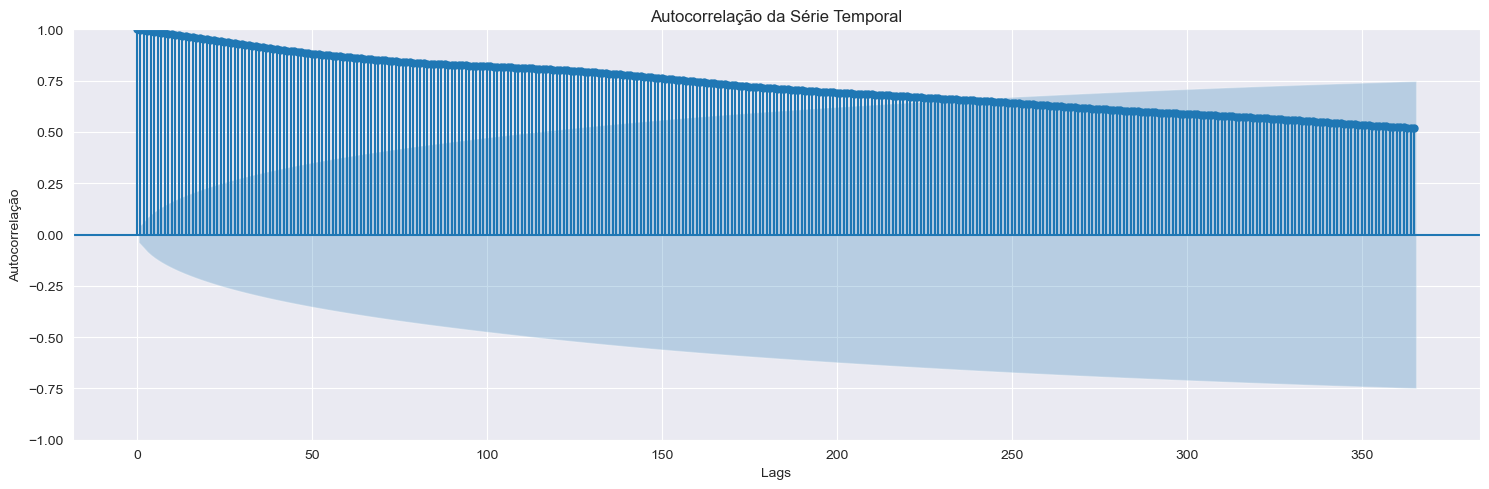

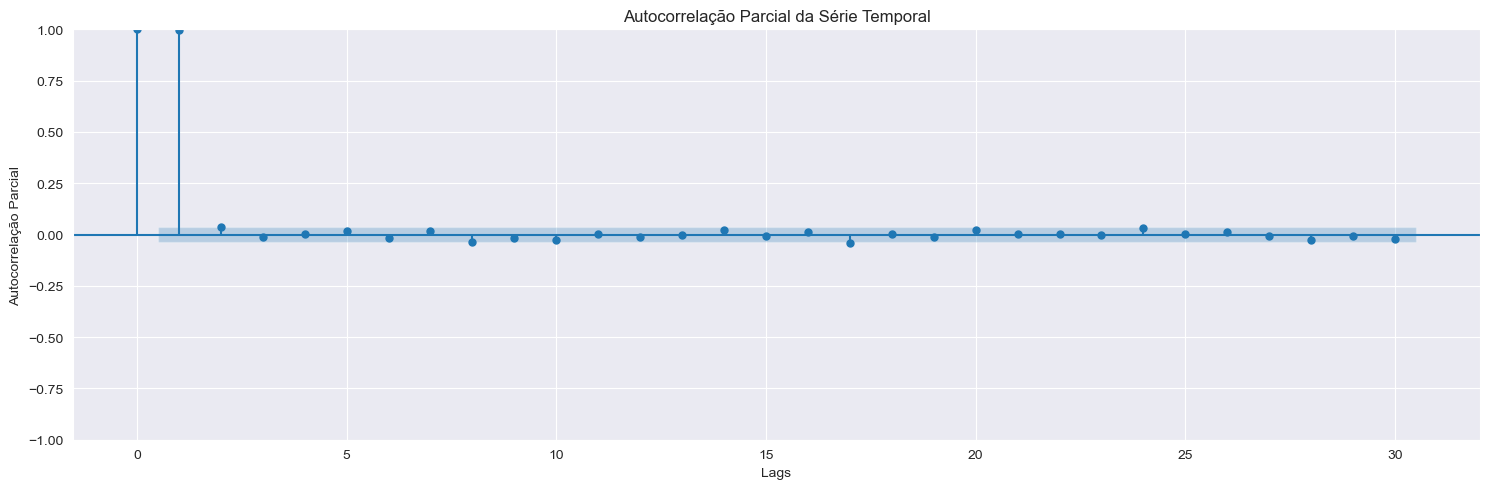

In [6]:
# EDA - Decomposição autoregressiva - Auto correlacao & Auto correlacao parcial

# ACF
fig, ax = plt.subplots(figsize=(15, 5))
_plot_acf(df["close"], lags=365, ax=ax, alpha=0.05)
ax.set_title("Autocorrelação da Série Temporal")
ax.set_xlabel("Lags")
ax.set_ylabel("Autocorrelação")
fig.set_tight_layout(True)

#PACF
fig, ax = plt.subplots(figsize=(15, 5))
_plot_pacf(df["close"], lags=30, ax=ax, alpha=0.05)
ax.set_title("Autocorrelação Parcial da Série Temporal")
ax.set_xlabel("Lags")
ax.set_ylabel("Autocorrelação Parcial")
fig.set_tight_layout(True)

O teste de **Dickey-Fuller aumentado (ADF)** confirmou que a série original **não é estacionária**, exigindo transformação antes da modelagem.

In [7]:
# EDA - Aplicando Adfuller para avaliar estacionariedade dos dados
adf_result = adfuller(df["close"])

print("\033[1m 1° Teste ADF \033[0m")
print(f"Teste Estatistico: {adf_result[0]}")
print(f"p-Value: {adf_result[1]}")
print("Valores criticos:")

for key, value in adf_result[4].items():
    print(f"\t{key}: {value}")

if adf_result[1] < 0.05:
    print("A série temporal \033[1m é estacionária")
else:
    print("A série temporal \033[1m não é estacionária \033[1m")
# H° e nula, portanto a serie NAO e estacionaria

df["close"].plot()

 1° Teste ADF 
Teste Estatistico: -0.8043543043892009
p-Value: 0.8178396762685718
Valores criticos:
	1%: -3.4327564272279556
	5%: -2.8626031845697164
	10%: -2.567335967911981
A série temporal  não é estacionária 


--------------------------------------------------------------------

### 3. Feature Engineering

Para lidar com a não estacionariedade dos dados, apliquei diferenciação de primeira ordem tornando a série estacionária, conforme confirmado pelo segundo teste ADF (p-value < 0.05). Tambem foram exploradas abordagens de engenharia de atributos de acordo com o modelo:

**Para modelos clássicos de séries temporais:**
* Uso direto da série diferenciada
* Exploração de lags implícitos via ARIMA (parâmetros p, d, q)

**Para modelos baseados em machine learning (XGBoost):**
* Extração de atributos temporais: Ano, mês, dia, dia da semana  
* Criação de variáveis derivadas:
    * Retorno diário
    * Diferença entre fechamentos consecutivos

--------------------------------------------------------------------

 2° Teste ADF (serie diferenciada) 
Teste Estatistico: -16.8628123211258
p-Value: 1.0963035092950416e-29
Valores criticos:
	1%: -3.4327564272279556
	5%: -2.8626031845697164
	10%: -2.567335967911981
A série temporal  é estacionária 


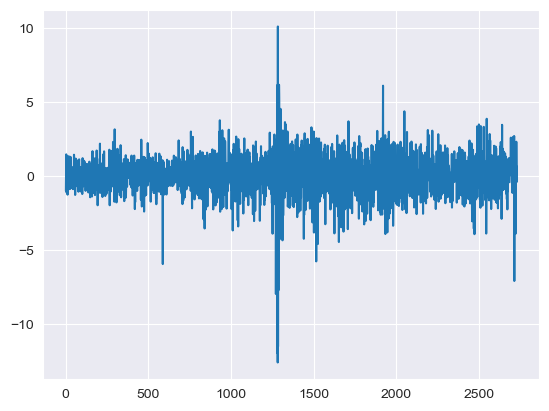

In [8]:
# Feature Engineering - Diferenciação para estacionariedade
adf_result = adfuller(df["close"].diff().dropna())
print("\033[1m 2° Teste ADF (serie diferenciada) \033[0m")
print(f"Teste Estatistico: {adf_result[0]}")
print(f"p-Value: {adf_result[1]}")
print("Valores criticos:")

for key, value in adf_result[4].items():
    print(f"\t{key}: {value}")

if adf_result[1] < 0.05:
    print("A série temporal \033[1m é estacionária \033[0m")
else:
    print("A série temporal \033[1m não é estacionária \033[0m")

df["close"].diff().plot()

In [9]:
# Feature Engineering - Coeficientes de autoregressão

# Serie diferenciada
df_diff = df["close"].diff().dropna()

#Coeficientes de autoregressão (parametros ARIMA)
acf_x = sm.tsa.acf(df_diff, alpha=0.05, nlags=30)
acf, ci = acf_x[:2]
q = np.where(abs(acf) < (ci[:, 1] - acf))[0][0]

pacf_x = sm.tsa.pacf(df_diff, alpha=0.05, nlags=30)
pacf, ci = pacf_x[:2]
p = np.where(abs(pacf) < (ci[:, 1] - pacf))[0][0]

d = 1

# parâmetros do modelo ARIMA
# p, d, q

### 4. Preparação da base para previsão

Os baselines, o ARIMA e o Prophet usam as primeiras 2.699 observações no ajuste e reservam os 30 últimos fechamentos para calcular os erros. A seleção de ordens do ARIMA consulta a série completa. O Prophet usa as aberturas observadas no teste e gera datas consecutivas de calendário.

Na implementação acadêmica do XGBoost, `xgb_train` e `xgb_test` recebem a mesma base. Além disso, `shift(-1)` nas variáveis `delta` e `daily_return` introduz informações do pregão seguinte. O erro desse ajuste descreve a amostra usada no treino.

In [10]:
# Preparação da base para previsão - Base de treino e teste
train_size = df.shape[0] - 30
train, test = df[:train_size], df[train_size:]

# Preparação dos dados para XGBoost
df_xgboost = df
df_xgboost["date"] = pd.to_datetime(df["date"])
df_xgboost["year"] = df["date"].dt.year
df_xgboost["month"] = df["date"].dt.month
df_xgboost["day"] = df["date"].dt.day
df_xgboost["dayofweek"] = df["date"].dt.dayofweek
df_xgboost["delta"] = df["close"].diff().shift(-1)
df_xgboost["daily_return"] = ((df["close"] - df["open"]) / df["open"]).shift(-1)
xgb_train = df_xgboost
xgb_test = df_xgboost

FEATURES = ["year", "month", "day", "dayofweek", "open", "delta", "daily_return"]
TARGET = "close"

--------------------------------------------------------------------

### 5. Escolha e Justificativa dos Modelos Utilizados

Foram testados múltiplos modelos para comparação:

**🔹 Modelos Baseline**
* Naive
* Seasonal Naive
* Seasonal Window Average

--------------------------------------------------------------------

**🔹 Modelos Estatísticos**

**ARIMA**
* Captura dependência temporal
* Utiliza diferenciação para lidar com tendência
* Ordens p e q estimadas pela ACF e PACF na série diferenciada, com d=1

**Prophet**  
* Modela tendência, sazonalidade e efeitos de calendário
* Adequado para séries de longo prazo

--------------------------------------------------------------------

**🔹 Modelo de Machine Learning**

**XGBoost Regressor**
* Capaz de capturar relações não lineares
* Utiliza atributos temporais e retornos
* Avaliado como alternativa mais flexível

--------------------------------------------------------------------

In [11]:
# Naive
y_train = train.set_index("date")["close"]
y_test  = test.set_index("date")["close"]

h = len(y_test)

# Naive: último valor do treino repetido
last_value = y_train.iloc[-1]

naive_preds = pd.Series(
    data=[last_value] * h,
    index=y_test.index
)

df_naive = metrics_to_df(
    calculate_metrics(y_test, naive_preds),
    model_name="Naive"
)

In [12]:
# SeasonalNaive
season_length = 5  # semana de pregão

seasonal_naive_preds = y_train.iloc[-season_length:].values
seasonal_naive_preds = np.tile(
    seasonal_naive_preds,
    int(np.ceil(h / season_length))
)[:h]

seasonal_naive_preds = pd.Series(
    seasonal_naive_preds,
    index=y_test.index
)

df_seasonal = metrics_to_df(
    calculate_metrics(y_test, seasonal_naive_preds),
    model_name="Seasonal Naive"
)

In [13]:
# SeasonalWindowAverage
k = 2  # número de janelas
season_length = 5

window = y_train.iloc[-k * season_length:]
window_avg = window.values.reshape(k, season_length).mean(axis=0)

seasonal_window_avg_preds = np.tile(
    window_avg,
    int(np.ceil(h / season_length))
)[:h]

seasonal_window_avg_preds = pd.Series(
    seasonal_window_avg_preds,
    index=y_test.index
)

df_window_avg = metrics_to_df(
    calculate_metrics(y_test, seasonal_window_avg_preds),
    model_name="Seasonal Window Avg"
)

In [14]:
# ARIMA
arima_model = ARIMA(
    y_train,
    order=(p, d, q)
)

arima_fit = arima_model.fit()
arima_preds = arima_fit.forecast(steps=h)
arima_preds.index = y_test.index

df_arima = metrics_to_df(
    calculate_metrics(y_test, arima_preds),
    model_name="ARIMA"
)

In [15]:
# Prophet
train_prophet = train.rename(columns={"date": "ds", "close": "y"})
test_prophet = test.rename(columns={"date": "ds", "close": "y"})

model = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
model.add_regressor("open")
model.fit(train_prophet)

future = model.make_future_dataframe(periods=len(test))
future["open"] = pd.concat([train["open"], test["open"]], ignore_index=True)
forecast = model.predict(future)

prophet_preds = forecast[["ds", "yhat"]].tail(len(test))
prophet_preds = prophet_preds.set_index("ds")
y_test = test_prophet.set_index("ds")["y"]

df_prophet = metrics_to_df(
    calculate_metrics(y_test, prophet_preds["yhat"]),
    model_name="Prophet"
)

In [16]:
# XGBoost
X_train, y_train = xgb_train[FEATURES], xgb_train[TARGET]
X_test, y_test = xgb_test[FEATURES], xgb_test[TARGET]

reg = xgb.XGBRegressor(objective="reg:squarederror")
reg.fit(X_train, y_train)
xgb_preds = reg.predict(X_test)

df_xgboost = metrics_to_df(
    calculate_metrics(y_test, xgb_preds),
    model_name="XGBoost"
)

--------------------------------------------------------------------

### 6. Resultados e Análise de Métricas

Os modelos foram avaliados utilizando métricas de regressão:
* MAE (Mean Absolute Error)
* MSE (Mean Squared Error)
* MAPE (%)

--------------------------------------------------------------------

In [17]:
results_df = pd.concat([
    df_naive,
    df_seasonal,
    df_window_avg,
    df_arima,
    df_prophet,
    df_xgboost
])

results_df.sort_values("MAPE (%)")

,MAE,MSE,MAPE (%)
XGBoost,0.313553,0.182954,0.354880
ARIMA,2.108007,7.201259,1.316630
Naive,2.144333,7.378130,1.339267
Seasonal Naive,2.811667,11.860292,1.759395
Prophet,3.006000,15.693661,1.894778
Seasonal Window Avg,4.883067,29.572904,3.059180


O MAPE mede o erro percentual absoluto médio de fechamento. A tabela reúne experimentos com protocolos diferentes. Os três baselines compartilham a mesma janela temporal. O XGBoost foi ajustado e avaliado nas mesmas linhas com informação futura. O Prophet foi pontuado por posição, embora as datas previstas em dias corridos possam divergir dos pregões do teste. A seleção das ordens do ARIMA também usou o histórico completo.

### 7. Modelo final e cenário de tendência

O experimento ajusta o XGBoost ao histórico e gera um cenário para as próximas cinco datas de segunda a sexta-feira. A abertura fica fixa, com diferença entre fechamentos e retorno diário definidos como zero. A seta compara duas estimativas consecutivas, a partir da segunda linha. O calendário usado é o do pandas e pode incluir feriados da bolsa.

In [18]:
X_full = xgb_train[FEATURES]
y_full = xgb_train[TARGET]

reg = xgb.XGBRegressor(objective="reg:squarederror", random_state=42)
reg.fit(X_full, y_full)

h = 5
last_date = df["date"].iloc[-1]

future_dates = pd.bdate_range(
    start=last_date + pd.Timedelta(days=1),
    periods=h
)

last_row = xgb_train.iloc[-1]
future_df = pd.DataFrame({
    "year": future_dates.year,
    "month": future_dates.month,
    "day": future_dates.day,
    "dayofweek": future_dates.dayofweek,
    "open": last_row["open"],
    "delta": 0,            # não conhecido → neutro
    "daily_return": 0      # não conhecido → neutro
})

future_forecast = reg.predict(future_df)

In [19]:
plt.figure(figsize=(14, 6))

# Histórico recente
plt.plot(
    df["date"].iloc[-360:],
    df["close"].iloc[-360:],
    label="Histórico"
)

# Previsão XGBoost
plt.plot(
    future_dates,
    future_forecast,
    label="Previsão XGBoost",
    linestyle="--"
)

plt.title("Previsão XGBoost - IBOVESPA")
plt.xlabel("Data")
plt.ylabel("Fechamento")
plt.legend()
plt.show()

In [20]:
forecast_df = pd.DataFrame({
    "date": future_dates,
    "forecast_close": future_forecast
})

forecast_df["trend"] = forecast_df["forecast_close"].diff().apply(
    lambda x: "↑" if x > 0 else ("↓" if x < 0 else "-")
)

forecast_df["dia"] = range(1, h + 1)
forecast_df["forecast_close"] = forecast_df["forecast_close"].round(3)

final_output = forecast_df[["dia", "forecast_close", "trend"]]
final_output = final_output.rename(columns={
    "dia": "Dia",
    "forecast_close": "Fechamento",
    "trend": "Tendencia"
})

final_output

,Dia,Fechamento,Tendencia
0,1,159.854004,-
1,2,152.257004,↓
2,3,153.863007,↑
3,4,151.462006,↓
4,5,152.195007,↑


### 8. Interpretação técnica

O XGBoost explorou relações não lineares entre fechamento, abertura e variáveis de calendário. O vazamento de informação descrito na seção 4 impede estimar, com esse experimento, sua capacidade de generalizar para outro período. Nos três baselines, as previsões dependem apenas dos fechamentos do treino.

### 9. Conclusão

A avaliação permite comparar três maneiras simples de projetar os próximos 30 fechamentos a partir de uma única data de corte. Entre elas, repetir o último fechamento apresentou o menor MAPE. Para comparar o XGBoost com esses modelos, seria preciso refazer os atributos dispondo apenas de informações conhecidas na data de emissão e reservar os mesmos pregões para avaliação.